# 3 STATISTICAL ANALYSIS

**Project:** Irish Company Survival: Registrations, Cohort Survival and Prediction

**Author:** Temuulen Bulgan

### Purpose of this notebook
This notebook shows how many companies were registered each year, how many were still registered 1, 3 and 5 years later, which sectors survived best, and whether Dublin companies survive longer than companies in other counties. It adds confidence intervals to the survival rates, tests whether the sector mix explains the Dublin gap, and checks whether the results depend on the definition of "closed" and the start year.

### Input
Tables in the SQL Server database `irish_company_survival` (loaded by notebook 2).

### Output
- Figures in `figures/` (`03_*.png`)
- Summary of findings and limitations at the end of this notebook

## Setup

In [28]:
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine, text
from statsmodels.stats.proportion import confint_proportions_2indep, proportion_confint

#### Connect to the database

In [5]:
# Connection to the local SQL Server database
connection_string = (
    "mssql+pyodbc://@localhost/irish_company_survival"
    "?driver=ODBC+Driver+18+for+SQL+Server"
    "&trusted_connection=yes"
    "&TrustServerCertificate=yes"
)
engine = create_engine(connection_string)

# Check the connection
with engine.connect() as conn:
    database_name = conn.execute(text("SELECT DB_NAME()")).scalar()

print("Connected to:", database_name)

Connected to: irish_company_survival


## 1. Load the data

I read one row per company from SQL. The query joins the fact table to the county, sector and status tables, so each company has its county, sector section and both closed flags. I use LEFT JOIN for county and sector so that companies without them are kept. Then I check the size, the missing values and the date range against notebook 2.

In [6]:
# One row per company, with county, sector and closed flags from the dimension tables
query = """
SELECT f.company_num,
       f.reg_date,
       f.closed_date,
       c.county,
       s.nace_section,
       s.section_name,
       st.closed,
       st.closed_strict
FROM fact_company AS f
LEFT JOIN dim_county AS c ON f.county_id = c.county_id
LEFT JOIN dim_sector AS s ON f.sector_id = s.sector_id
JOIN dim_status AS st ON f.status_id = st.status_id
"""
companies = pd.read_sql(text(query), engine, parse_dates=["reg_date", "closed_date"])

# Checks
print("Shape:", companies.shape, "\n")
print("Missing values:")
print(companies.isna().sum(), "\n")
print("Registration dates:", companies["reg_date"].min().date(), "to", companies["reg_date"].max().date())
print("Closing dates:     ", companies["closed_date"].min().date(), "to", companies["closed_date"].max().date())

Shape: (512008, 8) 

Missing values:
company_num           0
reg_date              0
closed_date      305953
county             1822
nace_section     246119
section_name     246119
closed                0
closed_strict         0
dtype: int64 

Registration dates: 2000-01-01 to 2026-10-27
Closing dates:      2000-07-13 to 2026-10-21


The table has 512,008 companies and 8 columns, the same as `fact_company` in notebook 2. 305,953 companies have no closing date, 1,822 have no county and 246,119 have no sector section. `nace_section` and `section_name` have the same number of missing values, so every company with a sector code has a section. Registration dates run from 2000-01-01 to 2026-10-27 and closing dates from 2000-07-13 to 2026-10-21.

## 2. Registrations per year

This section looks at how many companies were registered each year. I count the companies by registration year and check the totals against SQL Query 1.1.

In [7]:
# Year of registration, used for the yearly counts and later for the cohorts
companies["reg_year"] = companies["reg_date"].dt.year

# Number of companies registered each year
registrations = companies.groupby("reg_year").size()

# Checks against SQL Query 1.1
print("Years:", len(registrations))
print("Total:", registrations.sum(), "\n")
print(registrations)

Years: 27
Total: 512008 

reg_year
2000    18247
2001    14374
2002    13860
2003    14384
2004    15696
2005    17325
2006    19328
2007    18820
2008    14834
2009    13465
2010    14160
2011    14765
2012    14169
2013    15690
2014    17987
2015    19561
2016    21047
2017    22408
2018    22518
2019    22796
2020    21924
2021    25669
2022    21637
2023    22581
2024    23835
2025    26533
2026    24395
dtype: int64


There are 27 registration years, from 2000 to 2026, with 512,008 companies in total, the same as SQL Query 1.1. 2026 is not a full year: the data ends on 2026-10-27 (section 1), so its count of 24,395 covers less than ten months.

### 2.1 Chart of yearly registrations

The chart shows complete years only. The data ends on 2026-10-27, so 2026 is left out: its count would look like a fall. The dashed lines mark the Brexit referendum (2016) and the start of COVID-19 restrictions in Ireland (2020).

#### Background: Brexit and COVID-19

- The UK voted to leave the EU in a referendum on 23 June 2016.
- On 12 March 2020 the Irish Government closed schools, colleges and childcare and asked people to work from home where possible, the first COVID-19 restrictions in Ireland.

Sources: [Results of the 2016 UK EU membership referendum](https://en.wikipedia.org/wiki/Results_of_the_2016_United_Kingdom_European_Union_membership_referendum); [gov.ie, "Updated measures in response to COVID-19 (Coronavirus), Thursday 12 March"](https://www.gov.ie/en/department-of-health/publications/updated-measures-in-response-to-covid-19-coronavirus-thursday-12-march/)

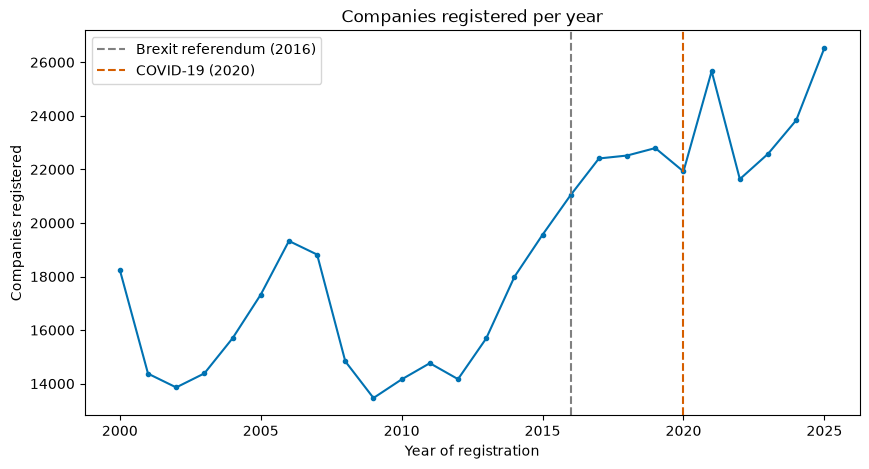

Years in chart: 2000 to 2025


In [8]:
# Last year in the data is not complete, so the chart stops one year before it
last_year = companies["reg_date"].max().year
complete_registrations = registrations.loc[:last_year - 1]

# Line chart of yearly registrations
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(complete_registrations.index, complete_registrations.values,
        marker="o", markersize=3, color="#0072B2")

# Brexit referendum and start of COVID-19
ax.axvline(2016, color="grey", linestyle="--", label="Brexit referendum (2016)")
ax.axvline(2020, color="#D55E00", linestyle="--", label="COVID-19 (2020)")

ax.set_title("Companies registered per year")
ax.set_xlabel("Year of registration")
ax.set_ylabel("Companies registered")
ax.legend()

fig.savefig("../figures/03_registrations_per_year.png", dpi=150, bbox_inches="tight")
plt.show()

# Check: years in the chart
print("Years in chart:", complete_registrations.index.min(), "to", complete_registrations.index.max())

Registrations fell from 18,247 in 2000 to 13,860 in 2002, rose to 19,328 in 2006 and fell to their lowest level, 13,465, in 2009. From 2010 they rose almost every year. In 2020 they dipped slightly, from 22,796 to 21,924, then rose to 25,669 in 2021 and fell to 21,637 in 2022. The highest year is 2025, with 26,533 companies. Registrations were already rising before 2016, so the chart alone does not show a Brexit effect.

### 2.2 Registrations by county

I count the companies in each county, for all registrations in the data (2000-01-01 to 2026-10-27, from section 1). Companies with no county are shown as `NaN`.

In [9]:
# Companies per county, largest first, including companies with no county
county_counts = companies["county"].value_counts(dropna=False)

# Dublin's share of all companies, in percent
dublin_share = county_counts.loc["DUBLIN"] / len(companies) * 100

print("Counties:", companies["county"].nunique())
print("Dublin share:", round(dublin_share, 1), "%\n")
print(county_counts)

Counties: 26
Dublin share: 44.4 %

county
DUBLIN       227457
CORK          51450
GALWAY        22117
KILDARE       19791
MEATH         17961
LIMERICK      17288
WICKLOW       13278
LOUTH         13191
DONEGAL       11492
WEXFORD       11477
KERRY         11368
TIPPERARY     11313
CLARE         10631
WATERFORD      8610
MAYO           8286
WESTMEATH      8200
KILKENNY       6905
CAVAN          5906
OFFALY         5411
LAOIS          5178
MONAGHAN       5129
CARLOW         4435
SLIGO          4239
ROSCOMMON      3957
LONGFORD       2838
LEITRIM        2278
NaN            1822
Name: count, dtype: int64


Companies are registered in all 26 counties. Dublin has 227,457 companies, 44.4% of the total, and Cork is second with 51,450. Leitrim has the fewest, 2,278. 1,822 companies have no county. The counts match SQL Query 1.3.

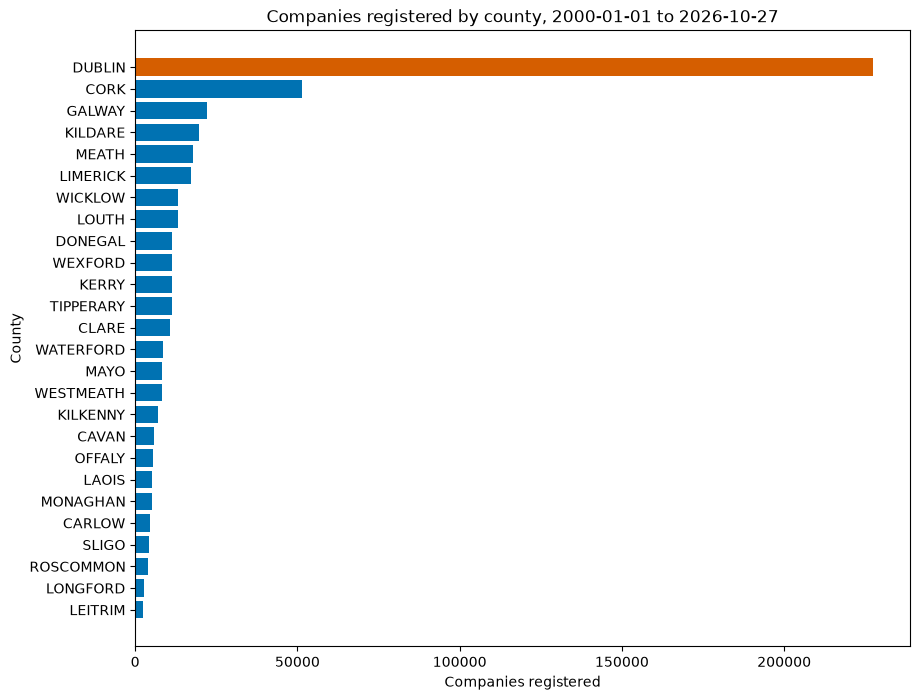

Counties in chart: 26


In [10]:
# Counties only (no missing values), smallest first so the largest bar is at the top
county_chart = companies["county"].value_counts().sort_values()

# Dublin in orange, all other counties in blue
bar_colours = ["#D55E00" if county == "DUBLIN" else "#0072B2" for county in county_chart.index]

# Horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(county_chart.index, county_chart.values, color=bar_colours)

# Period of the data, for the title
first_date = companies["reg_date"].min().date()
last_date = companies["reg_date"].max().date()
ax.set_title(f"Companies registered by county, {first_date} to {last_date}")
ax.set_xlabel("Companies registered")
ax.set_ylabel("County")

fig.savefig("../figures/03_registrations_by_county.png", dpi=150, bbox_inches="tight")
plt.show()

# Check: number of counties in the chart
print("Counties in chart:", len(county_chart))

Dublin's bar is much longer than any other county's. Most counties have far fewer companies than Dublin and Cork, so the comparison in section 5 is Dublin against all other counties together, not county by county.

### 2.3 Registrations by sector

Notebook 1 showed that most companies registered before 2015 have no sector code, so the sector counts use companies registered from 2016. Companies with no sector are shown as `NaN`.

In [11]:
# Sector codes are mostly missing before 2015 (notebook 1), so sectors use 2016 onwards
sector_start_year = 2016
recent = companies[companies["reg_year"] >= sector_start_year]

# Companies per sector, largest first, including companies with no sector
sector_counts = recent["section_name"].value_counts(dropna=False)

print("Companies from", sector_start_year, ":", len(recent))
print("Sectors:", recent["section_name"].nunique(), "\n")
print(sector_counts)

Companies from 2016 : 255343
Sectors: 21 

section_name
Professional services            40739
Finance and insurance            37803
Wholesale and retail             29048
Construction                     25855
Information and communication    22202
Administrative services          17284
Accommodation and food           14842
Other services                   13249
Real estate                      10135
Health and social work           10033
Agriculture                       7641
Manufacturing                     7012
Arts and recreation               6125
Transport                         4979
Education                         4358
NaN                               1614
Energy                            1230
Water and waste                    554
Public administration              341
Mining                             259
Extraterritorial bodies             26
Households                          14
Name: count, dtype: int64


255,343 companies were registered from 2016, and all 21 sectors appear. The largest sectors are Professional services (40,739), Finance and insurance (37,803) and Wholesale and retail (29,048). 1,614 companies have no sector. The counts match SQL Query 1.4.

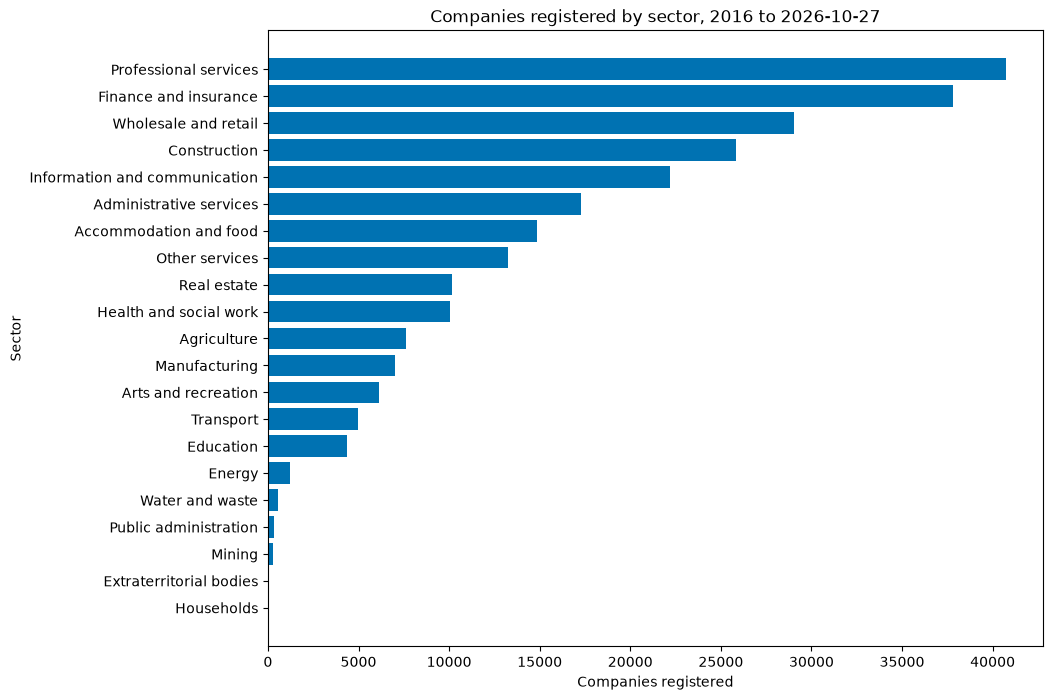

Sectors in chart: 21


In [12]:
# Sectors only (no missing values), smallest first so the largest bar is at the top
sector_chart = recent["section_name"].value_counts().sort_values()

# Horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(sector_chart.index, sector_chart.values, color="#0072B2")

ax.set_title(f"Companies registered by sector, {sector_start_year} to {last_date}")
ax.set_xlabel("Companies registered")
ax.set_ylabel("Sector")

fig.savefig("../figures/03_registrations_by_sector.png", dpi=150, bbox_inches="tight")
plt.show()

# Check: number of sectors in the chart
print("Sectors in chart:", len(sector_chart))

Professional services, Finance and insurance and Wholesale and retail are the three largest sectors. Several sectors at the bottom of the chart have very few companies, so section 4 ranks only sectors with at least 100 companies, the same rule as SQL Query 3.1.

### 2.4 Summary

- Registrations fell to their lowest level in 2009 (13,465) and rose almost every year from 2010. The highest year is 2025, with 26,533 companies.
- In 2020 registrations dipped slightly, then reached 25,669 in 2021 and fell back to 21,637 in 2022. Registrations were already rising before 2016, so the chart does not show a clear Brexit effect.
- Dublin has 227,457 companies, 44.4% of the total. No other county comes close.
- From 2016, the largest sectors are Professional services (40,739), Finance and insurance (37,803) and Wholesale and retail (29,048).

## 3. Survival by cohort

A cohort is all companies registered in the same year. For each cohort I calculate the share still registered 1, 3 and 5 years after registration.

A company can only be counted at an age it has already reached. A company registered in 2024 cannot show whether it survived 5 years, so it is left out of the 5-year share but counted in the 1-year share. This is the same rule as SQL Query 2.1, so the totals must match it.

### 3.1 Survival flags for each company

In [13]:
# Data date: the last date in the data, the same as the last day in dim_date
data_date = max(companies["reg_date"].max(), companies["closed_date"].max())

for years in [1, 3, 5]:
    # Date when the company reaches this age
    anniversary = companies["reg_date"] + pd.DateOffset(years=years)

    # The company is counted only if it reached this age by the data date
    eligible = anniversary <= data_date

    # Still registered at that age: never closed, or closed after the anniversary
    still_registered = companies["closed_date"].isna() | (companies["closed_date"] > anniversary)

    companies[f"eligible_{years}y"] = eligible
    companies[f"survived_{years}y"] = eligible & still_registered

# Checks against the totals of SQL Query 2.1
print("Data date:", data_date.date(), "\n")
for years in [1, 3, 5]:
    print(f"{years}-year: eligible", companies[f"eligible_{years}y"].sum(),
          "| survived", companies[f"survived_{years}y"].sum())

Data date: 2026-10-27 

1-year: eligible 482647 | survived 479263
3-year: eligible 433682 | survived 375053
5-year: eligible 388936 | survived 286668


The data date is 2026-10-27. 482,647 companies are old enough to count at 1 year, 433,682 at 3 years and 388,936 at 5 years. 479,263, 375,053 and 286,668 of them were still registered at that age. These totals match SQL Query 2.1.

### 3.2 Survival rates by cohort

I add up the flags for each registration year. The survival rate is the number still registered divided by the number old enough to be counted. It is empty when no company in the cohort is old enough yet.

In [14]:
# Eligible and surviving companies per cohort
flag_columns = ["eligible_1y", "survived_1y",
                "eligible_3y", "survived_3y",
                "eligible_5y", "survived_5y"]
cohorts = companies.groupby("reg_year")[flag_columns].sum()

# Survival rate in percent for each age
for years in [1, 3, 5]:
    survived = cohorts[f"survived_{years}y"]
    eligible = cohorts[f"eligible_{years}y"]
    cohorts[f"survival_{years}y_pct"] = (survived / eligible * 100).round(1)

# Check: totals against SQL Query 2.1
print(cohorts[flag_columns].sum(), "\n")
cohorts[["survival_1y_pct", "survival_3y_pct", "survival_5y_pct"]]

eligible_1y    482647
survived_1y    479263
eligible_3y    433682
survived_3y    375053
eligible_5y    388936
survived_5y    286668
dtype: int64 



,survival_1y_pct,survival_3y_pct,survival_5y_pct
reg_year,,,
2000,99.9,89.1,64.3
2001,100.0,89.5,67.2
2002,99.9,87.1,70.8
2003,99.6,87.5,73.1
2004,99.5,85.5,72.8
2005,99.5,86.0,72.0
2006,99.3,85.1,70.4
2007,99.2,80.8,65.1
2008,99.1,77.0,62.0


The six totals match SQL Query 2.1. 1-year survival is close to 99% in every cohort. 5-year survival was 64.3% for the 2000 cohort, 62.0% for 2008 and 70.9% for 2013. It rose to 74.3% for 2016 and 87.3% for 2019, and was 86.6% for 2021. Cohorts from 2022 are not old enough for a 5-year rate.

### 3.3 Chart of survival rates by cohort

Each line is one age. A line stops at the last cohort that is old enough for that age.

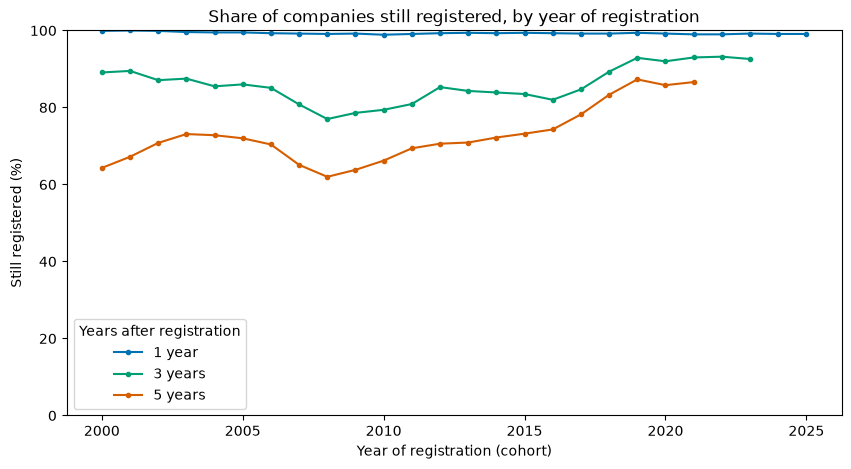

1 year - last cohort: 2025
3 years - last cohort: 2023
5 years - last cohort: 2021


In [16]:
# One line per age, Okabe-Ito colours
ages = {"survival_1y_pct": ("1 year", "#0072B2"),
        "survival_3y_pct": ("3 years", "#009E73"),
        "survival_5y_pct": ("5 years", "#D55E00")}

fig, ax = plt.subplots(figsize=(10, 5))
for column, (label, colour) in ages.items():
    ax.plot(cohorts.index, cohorts[column], marker="o", markersize=3,
            color=colour, label=label)

ax.set_title("Share of companies still registered, by year of registration")
ax.set_xlabel("Year of registration (cohort)")
ax.set_ylabel("Still registered (%)")
ax.set_ylim(0, 100)
ax.legend(title="Years after registration")

fig.savefig("../figures/03_survival_by_cohort.png", dpi=150, bbox_inches="tight")
plt.show()

# Check: last cohort on each line
for column, (label, colour) in ages.items():
    print(label, "- last cohort:", cohorts[column].last_valid_index())

Almost every company is still registered one year after registration. The gap opens later: 5-year survival was 62.0% for the 2008 cohort and rose to 87.3% for the 2019 cohort. The newest cohorts look the healthiest. Section 3.5 checks whether this is real or caused by fewer closures in recent years.

### 3.4 Confidence intervals for 5-year survival

Each cohort is one sample of companies, so its survival rate has some random variation. A 95% confidence interval shows the range the true rate is likely to be in. I use the Wilson interval, which works well for rates close to 100%.

In [18]:
# Cohorts old enough for a 5-year rate
five_year = cohorts[cohorts["eligible_5y"] > 0].copy()

# 95% Wilson confidence interval for each cohort
low, high = proportion_confint(five_year["survived_5y"], five_year["eligible_5y"],
                               alpha=0.05, method="wilson")
five_year["ci_low_pct"] = (low * 100).round(1)
five_year["ci_high_pct"] = (high * 100).round(1)

# Width of each interval in percentage points
five_year["ci_width"] = five_year["ci_high_pct"] - five_year["ci_low_pct"]

print("Cohorts:", len(five_year))
print("Widest interval:", five_year["ci_width"].max().round(1), "percentage points\n")
five_year[["eligible_5y", "survival_5y_pct", "ci_low_pct", "ci_high_pct"]]

Cohorts: 22
Widest interval: 1.6 percentage points



,eligible_5y,survival_5y_pct,ci_low_pct,ci_high_pct
reg_year,,,,
2000,18247,64.3,63.6,65.0
2001,14374,67.2,66.5,68.0
2002,13860,70.8,70.0,71.5
2003,14384,73.1,72.4,73.8
2004,15696,72.8,72.1,73.5
2005,17325,72.0,71.3,72.7
2006,19328,70.4,69.8,71.0
2007,18820,65.1,64.4,65.8
2008,14834,62.0,61.2,62.8


The 22 cohorts from 2000 to 2021 have a 5-year rate. The intervals are narrow, the widest is about 1.6 percentage points, because each cohort has thousands of companies. The differences between cohorts in the chart, for example 62.0% for 2008 and 87.3% for 2019, are much larger than this, so they are not due to random variation. The interval only covers random variation. It does not show errors in the data, such as closures that were recorded late.

### 3.5 Check: closures per year

The newest cohorts have the highest 5-year survival. This could be real, or companies may have been removed from the register later than usual. To check, I count closures by the year of the closing date. The counts should match SQL Query 2.2.

In [19]:
# Closed companies only
closed_companies = companies[companies["closed_date"].notna()]

# Number of closures in each closing year
closures = closed_companies.groupby(closed_companies["closed_date"].dt.year).size()

# Checks against SQL Query 2.2
print("Total closures:", closures.sum(), "\n")
print(closures)

Total closures: 206055 

closed_date
2000       13
2001        6
2002     1837
2003     2897
2004     3354
2005     7349
2006     5235
2007     5575
2008     6991
2009     8490
2010     9646
2011    11002
2012    10392
2013    10320
2014     9917
2015     6867
2016    11985
2017    10467
2018    12382
2019    11226
2020     7734
2021     7939
2022     7442
2023     7142
2024     8134
2025     9029
2026    12684
dtype: int64


There are 206,055 closures in total, the same as SQL Query 2.2. From 2016 to 2019 there were between 10,467 and 12,382 closures a year. From 2020 to 2023 there were fewer, between 7,142 and 7,939 a year. In 2026, with data only up to October, there were already 12,684 closures, the most of any year. Closures fell and then rose sharply. If companies that stopped trading were removed from the register later than usual, they still count as registered at their 5-year date. So the 5-year rates of the most recent cohorts may be too high.

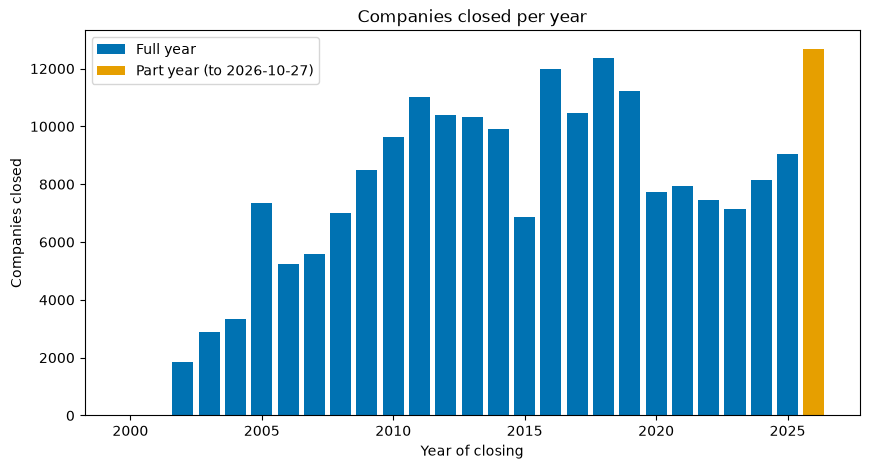

Years in chart: 2000 to 2026


In [20]:
# Last closing year is not complete, so it gets its own colour
last_closing_year = closures.index.max()
full_years = closures.loc[:last_closing_year - 1]

# Bar chart of closures per year
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(full_years.index, full_years.values, color="#0072B2", label="Full year")
ax.bar(last_closing_year, closures.loc[last_closing_year], color="#E69F00",
       label=f"Part year (to {data_date.date()})")

ax.set_title("Companies closed per year")
ax.set_xlabel("Year of closing")
ax.set_ylabel("Companies closed")
ax.legend()

fig.savefig("../figures/03_closures_per_year.png", dpi=150, bbox_inches="tight")
plt.show()

# Check: years in the chart
print("Years in chart:", closures.index.min(), "to", last_closing_year)

The chart shows the dip in closures from 2020 to 2023 and the sharp rise after it. The orange 2026 bar covers less than a full year but is still the tallest. This pattern fits closures that were held back for some years and then caught up. It is a reason to treat the high 5-year survival of the most recent cohorts with caution.

### 3.6 Sensitivity check: strict closed rule

Companies listed for strike-off or in liquidation are still on the register, so the main rule counts them as survived. They have no closing date. This check counts them as closed before their 5-year date, the worst case. If the cohort pattern stays the same, the result does not depend on the closed rule.

In [21]:
# Companies on their way off the register: closed under the strict rule only
on_way_out = companies["closed_strict"] & ~companies["closed"]

# Worst case: count them as closed before their 5-year date
companies["survived_5y_strict"] = companies["survived_5y"] & ~on_way_out

# 5-year survival per cohort under the strict rule (rows matched by cohort year)
strict_survived = companies.groupby("reg_year")["survived_5y_strict"].sum()
five_year["survival_5y_strict_pct"] = (strict_survived / five_year["eligible_5y"] * 100).round(1)

# Change from the main rule, in percentage points
five_year["difference"] = (five_year["survival_5y_strict_pct"] - five_year["survival_5y_pct"]).round(1)

print("Companies on their way off the register:", on_way_out.sum())
print("Largest drop:", five_year["difference"].min(), "points, cohort", five_year["difference"].idxmin(), "\n")
five_year[["survival_5y_pct", "survival_5y_strict_pct", "difference"]]

Companies on their way off the register: 17045
Largest drop: -9.4 points, cohort 2020 



,survival_5y_pct,survival_5y_strict_pct,difference
reg_year,,,
2000,64.3,62.7,-1.6
2001,67.2,65.5,-1.7
2002,70.8,68.9,-1.9
2003,73.1,70.9,-2.2
2004,72.8,70.5,-2.3
2005,72.0,69.5,-2.5
2006,70.4,68.2,-2.2
2007,65.1,62.9,-2.2
2008,62.0,59.9,-2.1


17,045 companies are listed for strike-off or in liquidation but have no closing date. Counting them as closed lowers the 5-year rate of every cohort. The drop is small for the oldest cohorts, 1.6 points for 2000, and grows for the recent ones, up to 9.4 points for 2020. So part of the high survival of recent cohorts comes from companies that are still on the register but on their way off it. The pattern stays the same: under the strict rule, 5-year survival is 59.9% for 2008 and 79.3% for 2019. This check is a worst case. A company listed for strike-off now may still have been trading at its 5-year date, especially in the older cohorts.

### 3.7 Summary

- Almost every company is still registered one year after registration: 1-year survival is close to 99% in every cohort from 2000 to 2025.
- 5-year survival was lowest for the 2008 cohort (62.0%) and highest for the 2019 cohort (87.3%). The recent cohorts have the highest 5-year rates.
- The 95% confidence intervals are at most 1.6 percentage points wide, so the differences between cohorts are not due to random variation.
- Closures fell from 10,467–12,382 a year in 2016–2019 to 7,142–7,939 a year in 2020–2023, then rose to 12,684 in 2026 (to October). Companies may have been removed from the register later than usual, which makes the recent 5-year rates too high.
- 17,045 companies are listed for strike-off or in liquidation. Counting them as closed lowers 5-year survival by up to 9.4 points (2020 cohort), but the pattern stays: 59.9% for 2008 and 79.3% for 2019 under the strict rule.
- Survival after 5 years has improved for recent cohorts, but part of the rise comes from delayed closures, so the true improvement is likely smaller than the chart shows.

## 4. Survival by sector

This section compares 5-year survival between sectors. Sector codes are mostly missing before 2015 (notebook 1), so I use cohorts from 2016. I use only cohorts where every company is old enough for the 5-year rate, so each sector is measured over the same years. Sectors with fewer than 100 companies are left out, the same rule as SQL Query 3.1.

In [22]:
# Number of companies in each cohort
cohort_size = companies.groupby("reg_year").size()

# Full cohorts: every company in the cohort is old enough for the 5-year rate
full_cohorts = cohort_size.index[cohorts["eligible_5y"] == cohort_size]

# Full cohorts from the sector start year (section 2.3)
in_sector_period = (companies["reg_year"].isin(full_cohorts)
                    & (companies["reg_year"] >= sector_start_year))
sector_data = companies[in_sector_period]

# Eligible and surviving companies per sector (companies without a sector are dropped)
sectors = sector_data.groupby("section_name")[["eligible_5y", "survived_5y"]].sum()

# Only sectors with at least 100 companies, the same rule as SQL Query 3.1
min_companies = 100
sectors = sectors[sectors["eligible_5y"] >= min_companies].copy()

# 5-year survival rate in percent, highest first
sectors["survival_5y_pct"] = (sectors["survived_5y"] / sectors["eligible_5y"] * 100).round(1)
sectors = sectors.sort_values("survival_5y_pct", ascending=False)

# Checks against SQL Query 3.1
print("Cohorts:", sector_data["reg_year"].min(), "to", sector_data["reg_year"].max())
print("Companies:", len(sector_data))
print("No sector:", sector_data["section_name"].isna().sum())
print("Sectors with at least", min_companies, "companies:", len(sectors), "\n")
sectors

Cohorts: 2016 to 2020
Companies: 110693
No sector: 454
Sectors with at least 100 companies: 19 



,eligible_5y,survived_5y,survival_5y_pct
section_name,,,
Agriculture,3415,3256,95.3
Construction,10777,9645,89.5
Real estate,4567,3973,87.0
Public administration,107,93,86.9
Energy,511,435,85.1
Transport,2347,1996,85.0
Finance and insurance,16116,13647,84.7
Water and waste,240,203,84.6
Health and social work,3713,3061,82.4


The 2016 to 2020 cohorts have 110,693 companies old enough for the 5-year rate, and 454 of them have no sector. 19 sectors have at least 100 companies. Agriculture has the highest 5-year survival, 95.3%, followed by Construction (89.5%) and Real estate (87.0%). Information and communication has the lowest, 71.1%. The results match SQL Query 3.1.

### 4.1 Chart of 5-year survival by sector

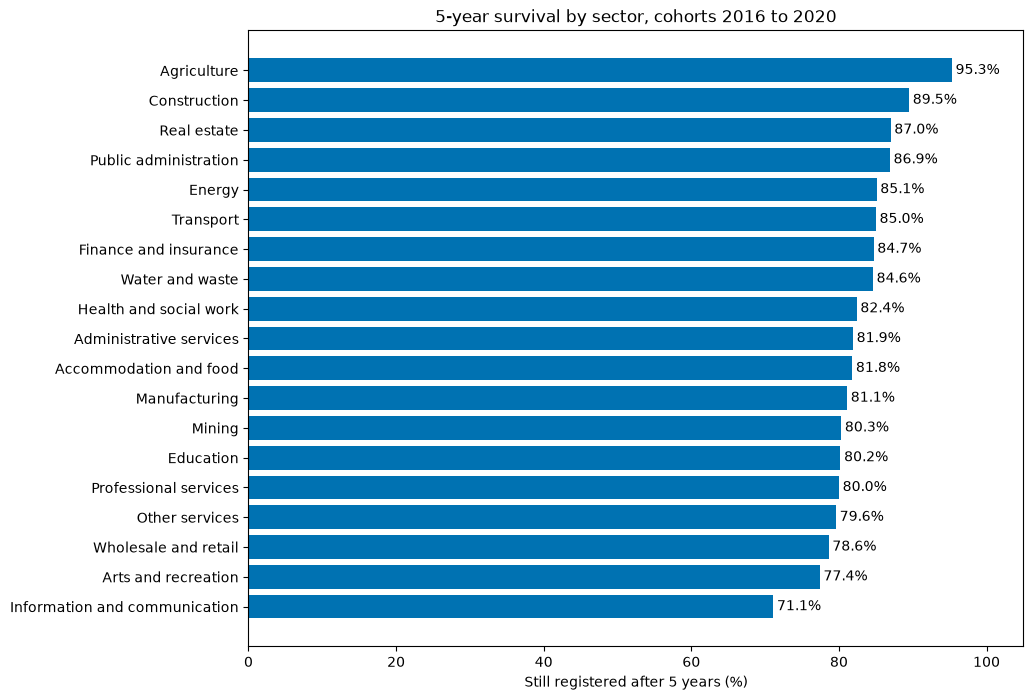

Sectors in chart: 19


In [23]:
# Lowest first, so the highest survival is at the top of the chart
survival_chart = sectors["survival_5y_pct"].sort_values()

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(survival_chart.index, survival_chart.values, color="#0072B2")

# Survival rate written at the end of each bar
for position, value in enumerate(survival_chart.values):
    ax.text(value + 0.5, position, f"{value:.1f}%", va="center")

# Cohort years taken from the data
first_cohort = sector_data["reg_year"].min()
last_cohort = sector_data["reg_year"].max()

ax.set_title(f"5-year survival by sector, cohorts {first_cohort} to {last_cohort}")
ax.set_xlabel("Still registered after 5 years (%)")
ax.set_xlim(0, 105)

fig.savefig("../figures/03_survival_by_sector.png", dpi=150, bbox_inches="tight")
plt.show()

# Check: number of sectors in the chart
print("Sectors in chart:", len(survival_chart))

Agriculture is at the top with 95.3% and Information and communication is at the bottom with 71.1%. All other sectors are between 77.4% (Arts and recreation) and 89.5% (Construction). Most companies in every sector are still registered after 5 years.

### 4.2 Confidence intervals for 5-year survival by sector

Some sectors have far fewer companies than others, so their survival rates are less certain. I use the same 95% Wilson interval as in section 3.4.

In [24]:
# 95% Wilson confidence interval for each sector
low, high = proportion_confint(sectors["survived_5y"], sectors["eligible_5y"],
                               alpha=0.05, method="wilson")
sectors["ci_low_pct"] = (low * 100).round(1)
sectors["ci_high_pct"] = (high * 100).round(1)

# Width of each interval in percentage points
sectors["ci_width"] = (sectors["ci_high_pct"] - sectors["ci_low_pct"]).round(1)

# Gap between the highest and the lowest sector (table is sorted highest first)
gap = (sectors["survival_5y_pct"].iloc[0] - sectors["survival_5y_pct"].iloc[-1]).round(1)

print("Gap between highest and lowest sector:", gap, "percentage points")
print("Widest interval:", sectors["ci_width"].max(), "points,", sectors["ci_width"].idxmax())
print("Narrowest interval:", sectors["ci_width"].min(), "points,", sectors["ci_width"].idxmin(), "\n")
sectors[["eligible_5y", "survival_5y_pct", "ci_low_pct", "ci_high_pct"]]

Gap between highest and lowest sector: 24.2 percentage points
Widest interval: 14.0 points, Mining
Narrowest interval: 1.1 points, Finance and insurance 



,eligible_5y,survival_5y_pct,ci_low_pct,ci_high_pct
section_name,,,,
Agriculture,3415,95.3,94.6,96.0
Construction,10777,89.5,88.9,90.1
Real estate,4567,87.0,86.0,87.9
Public administration,107,86.9,79.2,92.0
Energy,511,85.1,81.8,87.9
Transport,2347,85.0,83.5,86.4
Finance and insurance,16116,84.7,84.1,85.2
Water and waste,240,84.6,79.5,88.6
Health and social work,3713,82.4,81.2,83.6


The gap between the highest and the lowest sector is 24.2 percentage points. Large sectors have narrow intervals: the narrowest is 1.1 points, for Finance and insurance. Small sectors have wide intervals: the widest is 14.0 points, for Mining, which has only 122 companies. Public administration, with 107 companies, has an interval from 79.2% to 92.0%, so its place near the top is uncertain. The top and the bottom of the ranking are clear. Agriculture's interval (94.6% to 96.0%) is above every other sector, and Information and communication's interval (70.1% to 72.0%) is below every other sector. Many sectors in the middle have overlapping intervals, so their order should not be read too closely.

### 4.3 Summary

- For the 2016 to 2020 cohorts, 19 sectors have at least 100 companies. Agriculture has the highest 5-year survival (95.3%) and Information and communication the lowest (71.1%), a gap of 24.2 percentage points.
- Construction (89.5%) and Real estate (87.0%) are second and third. Arts and recreation (77.4%) and Wholesale and retail (78.6%) are just above the lowest sector.
- The top and the bottom of the ranking are clear: their confidence intervals do not overlap with any other sector. Many sectors in the middle overlap, so their order is less certain.
- Small sectors such as Mining (122 companies) and Public administration (107 companies) have wide intervals, so their rates should be read with care.
- These cohorts are the ones that section 3.5 showed may be affected by delayed closures, so all sector rates may be a little too high. The ranking compares sectors over the same years, so it is less affected than the rates themselves.

## 5. Dublin vs other counties

This section compares 5-year survival for companies in Dublin with companies in all other counties together. Section 2.2 showed that Dublin has far more companies than any other county, so I compare Dublin with the rest, not county by county. Companies without a county are left out, the same as SQL Query 4.1.

In [25]:
# Area: Dublin, other counties, or missing when the county is missing
companies["area"] = "Other counties"
companies.loc[companies["county"] == "DUBLIN", "area"] = "Dublin"
companies.loc[companies["county"].isna(), "area"] = None

# Companies, eligible and surviving companies per area (missing area is dropped)
areas = companies.groupby("area")[["eligible_5y", "survived_5y"]].sum()
areas["companies"] = companies.groupby("area").size()

# 5-year survival rate in percent
areas["survival_5y_pct"] = (areas["survived_5y"] / areas["eligible_5y"] * 100).round(1)

# Gap in percentage points: Dublin minus other counties
gap_area = (areas.loc["Dublin", "survival_5y_pct"]
            - areas.loc["Other counties", "survival_5y_pct"]).round(1)

# Checks against SQL Query 4.1
print("Companies with an area:", areas["companies"].sum())
print("Gap (Dublin minus other counties):", gap_area, "percentage points\n")
areas[["companies", "eligible_5y", "survived_5y", "survival_5y_pct"]]

Companies with an area: 510186
Gap (Dublin minus other counties): -5.5 percentage points



,companies,eligible_5y,survived_5y,survival_5y_pct
area,,,,
Dublin,227457,174073,123116,70.7
Other counties,282729,213357,162533,76.2


510,186 companies have a county. 70.7% of Dublin companies that are old enough were still registered after 5 years, against 76.2% in the other counties, a gap of -5.5 percentage points. Dublin companies do not survive longer; they survive less. The results match SQL Query 4.1. This figure pools all cohorts from 2000 to 2021, and survival changed a lot between cohorts (section 3), so the next step compares Dublin and the other counties cohort by cohort.

### 5.1 Survival by cohort, Dublin vs other counties

I calculate the 5-year survival rate for each cohort and area. If Dublin is lower in every cohort, the gap in section 5 is not caused by Dublin having more companies in the weak cohorts.

In [26]:
# Eligible and surviving companies per cohort and area
by_cohort = companies.groupby(["reg_year", "area"])[["eligible_5y", "survived_5y"]].sum()

# Only cohorts old enough for a 5-year rate
by_cohort = by_cohort[by_cohort["eligible_5y"] > 0].copy()

# 5-year survival rate in percent
by_cohort["survival_5y_pct"] = (by_cohort["survived_5y"] / by_cohort["eligible_5y"] * 100).round(1)

# One row per cohort, one column per area
area_rates = by_cohort["survival_5y_pct"].unstack()

# Gap in percentage points: Dublin minus other counties
area_rates["gap"] = (area_rates["Dublin"] - area_rates["Other counties"]).round(1)

# Checks against SQL Query 4.2
print("Cohorts:", len(area_rates))
print("Cohorts where Dublin is lower:", (area_rates["gap"] < 0).sum())
print("Largest gap:", area_rates["gap"].min(), "points, cohort", area_rates["gap"].idxmin())
print("Smallest gap:", area_rates["gap"].max(), "points, cohort", area_rates["gap"].idxmax(), "\n")
area_rates

Cohorts: 22
Cohorts where Dublin is lower: 22
Largest gap: -9.4 points, cohort 2000
Smallest gap: -1.9 points, cohort 2006 



area,Dublin,Other counties,gap
reg_year,,,
2000,59.7,69.1,-9.4
2001,63.2,70.5,-7.3
2002,67.2,73.7,-6.5
2003,70.4,74.9,-4.5
2004,69.6,75.0,-5.4
2005,68.3,74.5,-6.2
2006,69.2,71.1,-1.9
2007,61.8,67.3,-5.5
2008,60.3,63.2,-2.9


Dublin has lower 5-year survival than the other counties in all 22 cohorts. The largest gap is -9.4 percentage points, for 2000 (59.7% against 69.1%), and the smallest is -1.9 points, for 2006. For the most recent cohort, 2021, the rates are 83.9% and 88.9%. Dublin is lower in every cohort, so the overall gap in section 5 is not caused by the mix of cohorts.

### 5.2 Chart of survival by cohort, Dublin vs other counties

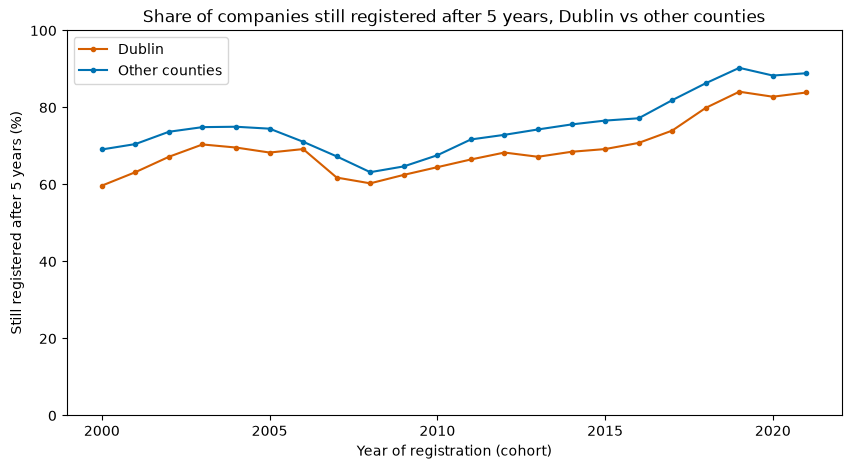

Cohorts in chart: 2000 to 2021


In [27]:
# One line per area, Dublin in the same orange as the county chart in section 2.2
area_colours = {"Dublin": "#D55E00", "Other counties": "#0072B2"}

fig, ax = plt.subplots(figsize=(10, 5))
for area, colour in area_colours.items():
    ax.plot(area_rates.index, area_rates[area], marker="o", markersize=3,
            color=colour, label=area)

ax.set_title("Share of companies still registered after 5 years, Dublin vs other counties")
ax.set_xlabel("Year of registration (cohort)")
ax.set_ylabel("Still registered after 5 years (%)")
ax.set_ylim(0, 100)
ax.legend()

fig.savefig("../figures/03_survival_dublin_vs_other.png", dpi=150, bbox_inches="tight")
plt.show()

# Check: cohorts in the chart
print("Cohorts in chart:", area_rates.index.min(), "to", area_rates.index.max())

The Dublin line is below the other counties line in every cohort from 2000 to 2021. Both lines follow the same pattern as section 3: a dip for the cohorts around 2008 and a rise for the recent cohorts. The gap is widest at the start and smallest around 2006.

### 5.3 Confidence interval for the Dublin gap

The gap of -5.5 percentage points in section 5 comes from two samples of companies, so it has some random variation. I calculate a 95% confidence interval for the difference between the two rates. The Newcombe method is built from two Wilson intervals, the same method used in sections 3.4 and 4.2.

In [29]:
# Rows for Dublin and the other counties from the section 5 table
dublin = areas.loc["Dublin"]
other = areas.loc["Other counties"]

# 95% confidence interval for the difference: Dublin rate minus other counties rate
low, high = confint_proportions_2indep(dublin["survived_5y"], dublin["eligible_5y"],
                                       other["survived_5y"], other["eligible_5y"],
                                       compare="diff", method="newcomb")

print("Gap (Dublin minus other counties):", gap_area, "percentage points")
print("95% CI:", round(low * 100, 1), "to", round(high * 100, 1), "percentage points")

Gap (Dublin minus other counties): -5.5 percentage points
95% CI: -5.7 to -5.2 percentage points


The 95% confidence interval for the gap is -5.7 to -5.2 percentage points. The whole interval is below zero and narrow, so the gap is not due to random variation. The interval does not show why Dublin is lower. One possible reason is that Dublin has more companies in sectors with low survival, which the next section tests.

### 5.4 Does the sector mix explain the Dublin gap?

If Dublin has more companies in sectors with low survival, it would have a lower overall rate even if each sector did equally well in Dublin and elsewhere. First I compare the sector mix of the two areas. I use the same companies as section 4 (full cohorts from 2016, the 19 ranked sectors), because sector codes are mostly missing before that.

In [30]:
# Section 4 companies that have an area and one of the 19 ranked sectors
in_mix = (in_sector_period
          & companies["area"].notna()
          & companies["section_name"].isin(sectors.index))
mix_data = companies[in_mix]

# Eligible companies per sector and area, one column per area
mix = mix_data.groupby(["section_name", "area"])["eligible_5y"].sum().unstack()

# Share of each area's companies in each sector (each column adds up to 100)
mix_pct = (mix / mix.sum() * 100).round(1)
mix_pct = mix_pct.sort_values("Dublin", ascending=False)

print("Companies:", len(mix_data))
print("Smallest sector and area group:", mix.min().min(), "\n")
mix_pct

Companies: 109888
Smallest sector and area group: 40 



area,Dublin,Other counties
section_name,,
Finance and insurance,20.7,9.4
Professional services,16.2,17.0
Information and communication,10.4,6.3
Wholesale and retail,9.7,12.3
Administrative services,7.9,4.5
Other services,7.5,7.9
Construction,6.6,12.5
Real estate,4.7,3.7
Accommodation and food,4.6,6.8


109,888 companies are in this comparison. The sector mix of Dublin is different from the other counties. Finance and insurance is 20.7% of Dublin companies against 9.4% elsewhere, and Information and communication is 10.4% against 6.3%. Agriculture is 0.4% of Dublin companies against 5.4% elsewhere, and Construction is 6.6% against 12.5%. Section 4 showed that Information and communication had the lowest 5-year survival and Agriculture and Construction the highest, so part of the Dublin gap could come from the sector mix. The next step measures how much.

#### Gap with the same sector mix

I calculate each area's 5-year survival rate in every sector. Then I average those rates using the same weights for both areas: the share of each sector among all companies in this comparison. If the gap stays about the same, the sector mix does not explain it. If it shrinks, part of the gap comes from the sector mix.

In [33]:
# Surviving companies per sector and area, one column per area
mix_survived = mix_data.groupby(["section_name", "area"])["survived_5y"].sum().unstack()

# 5-year survival rate per sector and area (survived divided by eligible)
sector_rates = mix_survived / mix

# Same weights for both areas: each sector's share of all companies in the comparison
sector_totals = mix["Dublin"] + mix["Other counties"]
weights = sector_totals / sector_totals.sum()

# Rates without adjustment: all surviving companies divided by all eligible companies
crude_dublin = mix_survived["Dublin"].sum() / mix["Dublin"].sum() * 100
crude_other = mix_survived["Other counties"].sum() / mix["Other counties"].sum() * 100

# Rates with the same sector mix: sector rates averaged with the same weights
same_mix_dublin = (sector_rates["Dublin"] * weights).sum() * 100
same_mix_other = (sector_rates["Other counties"] * weights).sum() * 100

# Rates rounded first, so the printed gap matches the printed rates
crude_dublin = round(crude_dublin, 1)
crude_other = round(crude_other, 1)
same_mix_dublin = round(same_mix_dublin, 1)
same_mix_other = round(same_mix_other, 1)

print("Weights add up to:", round(weights.sum(), 3), "\n")
print("Without adjustment: Dublin", crude_dublin, "| Other counties", crude_other,
      "| Gap", round(crude_dublin - crude_other, 1))
print("Same sector mix:    Dublin", same_mix_dublin, "| Other counties", same_mix_other,
      "| Gap", round(same_mix_dublin - same_mix_other, 1))

Weights add up to: 1.0 

Without adjustment: Dublin 78.4 | Other counties 84.9 | Gap -6.5
Same sector mix:    Dublin 78.6 | Other counties 84.5 | Gap -5.9


Without adjustment, Dublin's 5-year survival is 78.4% against 84.9% in the other counties, a gap of -6.5 percentage points. With the same sector mix for both areas, the rates are 78.6% and 84.5%, a gap of -5.9 points. The gap shrinks only a little, so the sector mix explains a small part of it. Dublin companies have lower survival than companies in the same sector in other counties.

### 5.5 Sensitivity checks for the Dublin gap

The gap in section 5 uses the main closed rule and all cohorts from 2000. I repeat it with two other choices: the strict closed rule from section 3.6, and cohorts from 2005 only, because the earliest cohorts are the most affected by registration dates that were overwritten after mergers (notebook 1). If Dublin is lower in every case, the result does not depend on these choices.

In [35]:
# Gap in 5-year survival (Dublin minus other counties) for a set of companies and a survival column
def dublin_gap(data, survived_column):
    eligible = data.groupby("area")["eligible_5y"].sum()
    survived = data.groupby("area")[survived_column].sum()
    rates = (survived / eligible * 100).round(1)
    gap = round(rates["Dublin"] - rates["Other counties"], 1)
    return rates["Dublin"], rates["Other counties"], gap

# Companies with an area, and the same companies from the check start year
check_start_year = 2005
with_area = companies[companies["area"].notna()]
from_check_year = with_area[with_area["reg_year"] >= check_start_year]

# One row per check
checks = pd.DataFrame(
    [dublin_gap(with_area, "survived_5y"),
     dublin_gap(with_area, "survived_5y_strict"),
     dublin_gap(from_check_year, "survived_5y")],
    index=["Main rule, from 2000",
           "Strict rule, from 2000",
           f"Main rule, from {check_start_year}"],
    columns=["dublin_pct", "other_pct", "gap"])

print("Checks where Dublin is lower:", (checks["gap"] < 0).sum(), "of", len(checks), "\n")
checks

Checks where Dublin is lower: 3 of 3 



,dublin_pct,other_pct,gap
"Main rule, from 2000",70.7,76.2,-5.5
"Strict rule, from 2000",65.8,72.9,-7.1
"Main rule, from 2005",71.9,77.1,-5.2


Dublin is lower in all 3 checks. With the strict closed rule, the rates are 65.8% and 72.9%, and the gap grows to -7.1 percentage points. With cohorts from 2005 only, the rates are 71.9% and 77.1%, a gap of -5.2 points, close to the main result of -5.5. So the Dublin gap does not depend on the closed rule or on the start year. The larger gap under the strict rule shows that Dublin also has relatively more companies listed for strike-off or in liquidation.

### 5.6 Summary

- Dublin companies do not survive longer than companies in other counties. 70.7% of Dublin companies were still registered after 5 years, against 76.2% elsewhere, a gap of -5.5 percentage points (95% confidence interval -5.7 to -5.2).
- Dublin is lower in all 22 cohorts from 2000 to 2021. The gap is largest for 2000 (-9.4 points) and smallest for 2006 (-1.9 points).
- Dublin has more companies in Finance and insurance and in Information and communication, and fewer in Agriculture and Construction. With the same sector mix for both areas, the gap for the 2016 to 2020 cohorts shrinks only from -6.5 to -5.9 points, so the sector mix explains a small part of it.
- The gap holds under the strict closed rule (-7.1 points) and for cohorts from 2005 (-5.2 points).
- The data shows that Dublin companies are less likely to stay registered, but not why.

## 6. Summary of findings

1. **Company registrations have grown since 2010.** Registrations fell to 13,465 in 2009 and reached their highest level in 2025, with 26,533 companies. They dipped slightly in 2020, then rose to 25,669 in 2021. Registrations were already rising before 2016, so the data does not show a clear Brexit effect (section 2).
2. **Almost every company survives its first year, and 5-year survival is higher for recent cohorts.** 1-year survival is close to 99% in every cohort. 5-year survival was 62.0% for the 2008 cohort and 87.3% for the 2019 cohort. Part of this rise comes from closures that were recorded late and from companies still on their way off the register: under the strict closed rule, 2019 falls to 79.3% (section 3).
3. **Agriculture has the highest 5-year survival and Information and communication the lowest.** For the 2016 to 2020 cohorts, Agriculture is at 95.3% and Information and communication at 71.1%, a gap of 24.2 percentage points. Their confidence intervals do not overlap with any other sector, but many sectors in the middle of the ranking do (section 4).
4. **Dublin companies survive less, not longer, than companies in other counties.** 70.7% of Dublin companies were still registered after 5 years, against 76.2% elsewhere (gap -5.5 points, 95% CI -5.7 to -5.2). Dublin is lower in all 22 cohorts. The sector mix explains only a small part of the gap (-6.5 to -5.9 points), and the gap holds under the strict closed rule and from 2005 (section 5).

**Limitations**
- "Survived" means still on the register, not still trading. Dormant companies count as survived.
- Closures fell in 2020 to 2023 and rose sharply after, so the 5-year rates of the most recent cohorts are probably too high.
- Sector codes are mostly missing before 2015, so sector results cover the 2016 to 2020 cohorts only. Sectors are chosen by the company, and broad codes such as management consultancy make Professional services larger.
- The county comes from the address text, and 1,822 companies have no county.
- Some companies that merged may have a registration date that was overwritten (notebook 1).
- The confidence intervals cover random variation only, not errors in the register.
- All counts match the October 2026 download of the CRO data.